# Ⅰ第2回 部屋B 学習率の実験

**問い**：学習率をどこまで大きくすると学習が壊れるか．一番よい学習率はどこか．

題材は第1回 GW3 試行①（FashionMNIST × MLP）．部屋Bのグループどうしで 9 つの学習率を分担し，全員分で 1 枚のグラフを作る．
1 条件の実行時間の目安は 5 エポックで 1〜2 分．

## (0) グループと役割の設定

In [1]:
# ===== (0) グループと役割の設定 =====
GROUP_ID = 3                  # ← 自分のグループ番号 (1〜27) に書き換える
MEMBER_ROLE = "recorder"   # implementer / verifier / recorder / presenter のいずれか（3 人・5 人グループの verifier は "verifier"）

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/ryuta/Lecture/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 学習が壊れ始める（検証正解率が 50% を切る）学習率：0.001
- 検証損失が一番小さくなる学習率：0.003

## (1) ライブラリのインポートと使用デバイス

In [2]:
import math
import time
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from common.device import get_device, synchronize
from common.fashion import loaders            # GW3 試行①と同じデータ（訓練 48,000 枚・検証 12,000 枚）
from common.logger import ResultLogger
from common.todo import todo_check, quiz_check
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
print("使用デバイス:", device)
from common.gradnorm import GradNormRecorder   # 部屋A で組み立てるものと同じ

使用デバイス: mps


## (確認) 実験の前に：用語の確認

授業ページの「勾配と学習率」を読んでから答える．**全問正解すると実験に進める**（ちがうとヒントが出る）．

**Q1**　勾配とは何か
- ア 損失の値そのもの
- イ 損失を小さくするには，重みをどちらへ，どれだけ動かせばよいかを表す数
- ウ 正解率がどれだけ上がったか

**Q2**　勾配が計算されるのは学習ループのどの行か
- ア outputs = model(images)
- イ loss.backward()
- ウ optimizer.step()

**Q3**　学習率（optim.Adam(..., lr=0.001) の lr）とは何か
- ア 学習に使うデータの割合
- イ 正解率の目標値
- ウ 勾配の方向へ重みを動かす 1 回の大きさ（一歩の大きさ）

In [3]:
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "イ"
Q2 = "イ"
Q3 = "ウ"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "86c731cb", "勾配は，重みを直す向きと量を表す．損失そのものではない"),
    "Q2": (Q2, "af2c0979", "backward で勾配を計算し，step でその勾配を使って重みを直す"),
    "Q3": (Q3, "7720d533", "小さすぎると進まず，大きすぎると行き過ぎて学習が壊れる"),
})

Q1：正解．勾配は，重みを直す向きと量を表す．損失そのものではない
Q2：正解．backward で勾配を計算し，step でその勾配を使って重みを直す
Q3：正解．小さすぎると進まず，大きすぎると行き過ぎて学習が壊れる
全問正解．実験に進んでよい


## (2) データ（GW3 試行①と同じ）

In [4]:
torch.manual_seed(0)
train_loader, val_loader = loaders(batch_size=64)
images, labels = next(iter(train_loader))
print("ミニバッチの形:", tuple(images.shape), "| 1 エポックのステップ数:", len(train_loader))

ミニバッチの形: (64, 1, 28, 28) | 1 エポックのステップ数: 750


## (3) 担当の学習率

In [5]:
LR_CHOICES = [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]   # 0.001 が第1回と同じ
LR = 0.00001          # ← 分担表で決めた学習率に書き換える
if LR not in LR_CHOICES:
    raise ValueError(f"LR は {LR_CHOICES} のどれかにする")

## (4) モデル・損失関数・最適化手法

モデルは GW3 試行①と同じ．変えるのは学習率だけ．

In [6]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 512), nn.ReLU(),
    nn.Linear(512, 256), nn.ReLU(),
    nn.Linear(256, 10),
).to(device)
criterion = nn.CrossEntropyLoss()
# TODO 1: 「...」を消して，GW3 の⑨と同じ Adam を，学習率 LR で作る
optimizer = optim.Adam(model.parameters(), lr=LR)
todo_check("TODO 1")
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0
)


## (5) 学習

「壊れた」の目安：検証正解率が **50% 未満**，または損失が `nan`（計算が壊れた）．
第1回の学習率 0.001 では 5 エポックで約 88% になる．

In [7]:
def validate(model):
    """検証データの損失と正解率（GW3 の⑪と同じ）"""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

EPOCHS = 5
recorder = GradNormRecorder(model)
train_losses, val_log = [], []

synchronize(device)
t0 = time.perf_counter()
for epoch in range(EPOCHS):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        recorder.record()             # 勾配の大きさを記録する（backward の後，step の前）
        optimizer.step()
        train_losses.append(loss.item())
    val_loss, val_acc = validate(model)
    val_log.append((val_loss, val_acc))
    print(f"エポック {epoch + 1}/{EPOCHS}  訓練損失 {sum(train_losses[-len(train_loader):]) / len(train_loader):.4f}"
          f"  検証損失 {val_loss:.4f}  検証正解率 {val_acc * 100:.2f}%")
synchronize(device)
train_sec = time.perf_counter() - t0
grads = recorder.to_frame()
print(f"学習時間 {train_sec:.1f} 秒 | 記録したステップ数 {len(grads)}")
diverged = (not math.isfinite(val_log[-1][0])) or val_log[-1][1] < 0.5
print("壊れた？:", "はい" if diverged else "いいえ")

エポック 1/5  訓練損失 1.6800  検証損失 1.1079  検証正解率 65.35%
エポック 2/5  訓練損失 0.9188  検証損失 0.8080  検証正解率 70.22%
エポック 3/5  訓練損失 0.7468  検証損失 0.7033  検証正解率 74.83%
エポック 4/5  訓練損失 0.6662  検証損失 0.6412  検証正解率 77.07%
エポック 5/5  訓練損失 0.6139  検証損失 0.5979  検証正解率 78.74%
学習時間 20.5 秒 | 記録したステップ数 3750
壊れた？: いいえ


## (6) グラフ：自分の学習率の損失と勾配

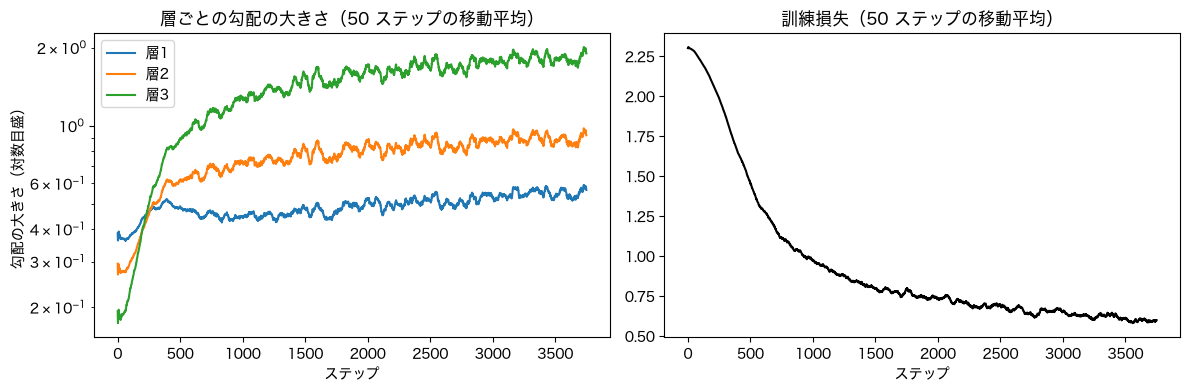

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grads.rolling(50, min_periods=1).mean().plot(ax=axes[0], logy=True)
axes[0].set_title("層ごとの勾配の大きさ（50 ステップの移動平均）")
axes[0].set_xlabel("ステップ"); axes[0].set_ylabel("勾配の大きさ（対数目盛）")
pd.Series(train_losses).rolling(50, min_periods=1).mean().plot(ax=axes[1], color="black")
axes[1].set_title("訓練損失（50 ステップの移動平均）"); axes[1].set_xlabel("ステップ")
plt.tight_layout(); plt.show()

## (7) 記録

In [9]:
metrics = {"val_loss": val_log[-1][0], "val_acc": val_log[-1][1], "train_sec": train_sec,
           "grad_start_first": grads.iloc[:100, 0].mean(), "grad_start_last": grads.iloc[:100, -1].mean(),
           "grad_end_first": grads.iloc[-100:, 0].mean(), "grad_end_last": grads.iloc[-100:, -1].mean()}
metrics["diverged"] = float(diverged)
logger = ResultLogger(GROUP_ID, MEMBER_ROLE, course="c1", day="d2", exercise="room_b", device=device)
logger.log_many(metrics, condition=f"lr={LR}", seed=0)
print("書き込み先:", logger.path)

書き込み先: /Users/ryuta/Lecture/AI_TD/results/c1_d2_room_b_03.csv


## (共有) CSV を部屋の仲間と集める

1. 自分の `results/c1_d2_room_b_<グループ>.csv` を，同じ部屋の仲間全員に送る（Slack・AirDrop など）
2. 受け取った CSV は，すべて `results/room_b_shared/` フォルダに入れる（無ければ作る．同じ名前のファイルは末尾に `_2` などを付けて別名にする）
3. もう 1 条件担当するときは，担当のセルを書き換えて，そこから下をもう一度実行する（同じ CSV に行が増える）

## (8) 全員分のグラフ（何回実行してもよい）

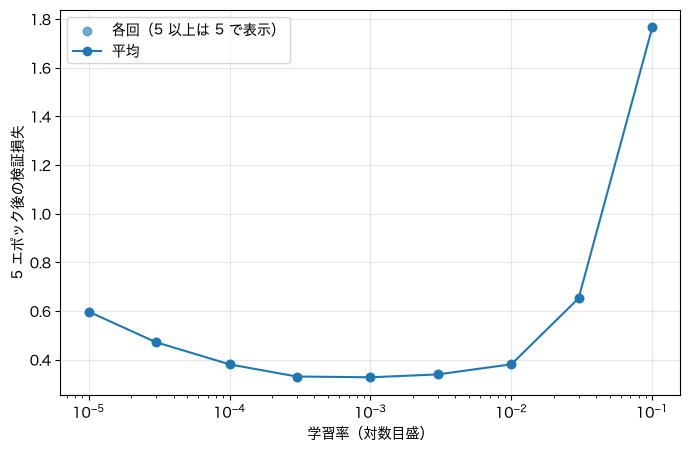

集まった学習率：9 / 9


metric_name,val_acc,val_loss,diverged,grad_start_last,grad_end_first
lr,,,,,
0.00001,0.7912,0.5969,0.0,0.2144,0.5806
0.00003,0.8342,0.4714,0.0,0.3481,0.7132
0.00010,0.8609,0.3803,0.0,0.8111,0.8778
0.00030,0.8755,0.3303,0.0,1.8040,0.8728
0.00100,0.8830,0.3271,0.0,2.5551,0.5802
0.00300,0.8732,0.3389,0.0,2.3069,0.3709
0.01000,0.8626,0.3805,0.0,2.2853,0.2615
0.03000,0.7668,0.6520,0.0,4.8564,0.1923
0.10000,0.1949,1.7659,1.0,37.3444,0.0129


In [10]:
import glob
files = glob.glob(str(ROOT / "results" / "c1_d2_room_b_*.csv")) + glob.glob(str(ROOT / "results" / "room_b_shared" / "*.csv"))
df = pd.concat([pd.read_csv(f) for f in files]).drop_duplicates()
wide = df.pivot_table(index=["group_id", "condition"], columns="metric_name", values="metric_value").reset_index()
wide["lr"] = wide["condition"].str.replace("lr=", "").astype(float)

plt.figure(figsize=(8, 5))
plt.scatter(wide["lr"], wide["val_loss"].clip(upper=5), alpha=0.6, label="各回（5 以上は 5 で表示）")
mean = wide.groupby("lr")["val_loss"].mean().clip(upper=5)
plt.plot(mean.index, mean.values, marker="o", label="平均")
plt.xscale("log"); plt.xlabel("学習率（対数目盛）"); plt.ylabel("5 エポック後の検証損失")
plt.grid(True, alpha=0.3); plt.legend(); plt.show()

print(f"集まった学習率：{wide['lr'].nunique()} / 9")
wide.groupby("lr")[["val_acc", "val_loss", "diverged", "grad_start_last", "grad_end_first"]].mean().round(4)

## (9) 報告（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．全体共有ではこの 3 つを 2 分で話す．

1. 壊れ始めた学習率と，検証損失が一番小さかった学習率．予測と比べてどうだったか：壊れ始めた学習率は0.1、検証損失が最も小さかった学習率は0.001だった、予測（壊れ始める：0.001，損失最小：0.003）とは異なった。
2. 小さすぎる学習率では何が起きたか：小さすぎる学習率ではパラメータの更新が小さくなり、学習が進みにくく、収束するまでに時間がかかった。
3. 壊れた学習率では，学習の最初の出力側の勾配（`grad_start_last`）と，最後の入力側の勾配（`grad_end_first`）は，うまくいった学習率と比べてどうだったか：壊れた学習率では、うまくいった学習率と比べてgrad_start_lastは大きく、grad_end_firstは小さくなった。